# Global Unemployment Rate Data Analysis and Prediction
## 全球失业率数据分析与预测

**Data Source:** International Labour Organization (ILO) — 189 countries, 2014-2024.

**Project Contents:**
1. Preliminary data analysis (distribution, mean, proportion, etc.)
2. Statistical tests (t-test, ANOVA)
3. 4 ML models (K-Means, Linear Regression, Random Forest, PCA)
4. 12 visualization charts (data exploration + model results)
5. All results saved to `output/` folder for Streamlit web display

---
## 1. Import Libraries

In [61]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')
import os, glob

OUTPUT_DIR = 'output'
os.makedirs(OUTPUT_DIR, exist_ok=True)
year_cols = [str(y) for y in range(2014, 2025)]
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'
print('All libraries loaded.')

All libraries loaded.


---
## 2. Data Loading

In [62]:
df = pd.read_csv('global_unemployment_data.csv')
print(f'Shape: {df.shape[0]} rows x {df.shape[1]} cols')
print(f'Countries: {df["country_name"].nunique()}')
print(f'Columns: {list(df.columns)}')
display(df.head())

Shape: 1134 rows x 16 cols
Countries: 189
Columns: ['country_name', 'indicator_name', 'sex', 'age_group', 'age_categories', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']


,country_name,indicator_name,sex,age_group,age_categories,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Afghanistan,Unemployment rate by sex and age,Female,15-24,Youth,13.340,15.974,18.570,21.137,20.649,20.154,21.228,21.640,30.561,32.200,33.332
1,Afghanistan,Unemployment rate by sex and age,Female,25+,Adults,8.576,9.014,9.463,9.920,11.223,12.587,14.079,14.415,23.818,26.192,28.298
2,Afghanistan,Unemployment rate by sex and age,Female,Under 15,Children,10.306,11.552,12.789,14.017,14.706,15.418,16.783,17.134,26.746,29.193,30.956
3,Afghanistan,Unemployment rate by sex and age,Male,15-24,Youth,9.206,11.502,13.772,16.027,15.199,14.361,14.452,15.099,16.655,18.512,19.770
4,Afghanistan,Unemployment rate by sex and age,Male,25+,Adults,6.463,6.879,7.301,7.728,7.833,7.961,8.732,9.199,11.357,12.327,13.087


---
## 3. Data Cleaning & Feature Engineering

In [63]:
# Handle missing values
missing = df[year_cols].isnull().sum().sum()
print(f'Missing values: {missing}')
if missing > 0:
    for col in year_cols:
        df[col] = df.groupby(['country_name', 'sex', 'age_group'])[col].transform(
            lambda x: x.fillna(x.mean()))
    df[year_cols] = df[year_cols].fillna(df[year_cols].mean())
print(f'Missing after cleaning: {df.isnull().sum().sum()}')

Missing values: 30
Missing after cleaning: 0


In [64]:
# Derived features
df['avg_unemployment'] = df[year_cols].mean(axis=1)
df['trend_2014_2024'] = df['2024'] - df['2014']
df['volatility'] = df[year_cols].std(axis=1)
df['max_unemployment'] = df[year_cols].max(axis=1)
df['min_unemployment'] = df[year_cols].min(axis=1)
df['covid_impact'] = df[['2020', '2021']].mean(axis=1) - df[['2018', '2019']].mean(axis=1)
print('7 derived features added.')
display(df[['country_name', 'sex', 'age_categories', 'avg_unemployment', 'trend_2014_2024', 'covid_impact']].head(8))

7 derived features added.


,country_name,sex,age_categories,avg_unemployment,trend_2014_2024,covid_impact
0,Afghanistan,Female,Youth,22.616818,19.992,1.0325
1,Afghanistan,Female,Adults,15.235000,19.722,2.3420
2,Afghanistan,Female,Children,18.145455,20.650,1.8965
3,Afghanistan,Male,Youth,14.959545,10.564,-0.0045
4,Afghanistan,Male,Adults,8.987909,6.624,1.0685
5,Afghanistan,Male,Children,10.889909,7.956,0.6805
6,Albania,Female,Youth,29.326364,-7.380,3.3415
7,Albania,Female,Adults,11.071818,-4.112,0.7525


---
## 4. Preliminary Data Analysis & Exploration Charts (Fig.1-8)
> Charts in this section describe the data itself — trends, distributions, comparisons.

### 4.1 Descriptive Statistics

In [65]:
desc_stats = df[year_cols].describe().round(3)
display(desc_stats)
desc_stats.to_csv(f'{OUTPUT_DIR}/descriptive_stats.csv', encoding='utf-8-sig')
print(f'Global mean range: {desc_stats.loc["mean"].min():.2f}% ~ {desc_stats.loc["mean"].max():.2f}%')

,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
count,1134.000,1134.000,1134.000,1134.000,1134.000,1134.000,1134.000,1134.000,1134.000,1134.000,1134.000
mean,11.388,11.272,11.123,10.864,10.516,10.311,11.851,11.423,10.340,9.985,9.940
std,11.119,10.916,10.743,10.641,10.528,10.298,11.232,10.873,10.238,9.935,9.925
min,0.027,0.034,0.038,0.035,0.044,0.036,0.056,0.064,0.067,0.063,0.060
25%,3.934,3.994,3.945,3.748,3.673,3.538,4.334,4.153,3.568,3.484,3.484
50%,7.698,7.547,7.504,7.140,6.706,6.627,8.067,7.542,6.624,6.505,6.495
75%,15.051,14.766,14.468,14.142,13.343,13.285,15.316,14.881,13.363,12.824,12.571
max,74.485,74.655,74.720,75.416,76.395,77.173,83.990,82.135,78.776,78.541,78.644


Global mean range: 9.94% ~ 11.85%


### 4.2 Fig.1 — Global Unemployment Rate Trend (Data Exploration)

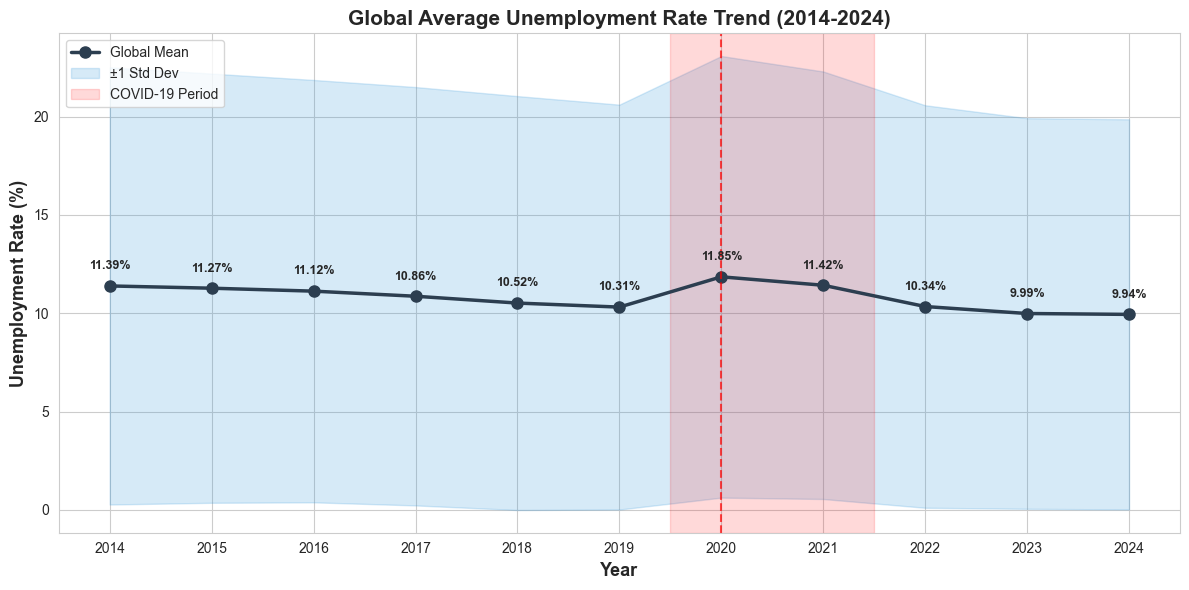

Fig.1: Global rate was stable 2014-2019, spiked in 2020 (COVID), declined 2021-2024.


In [66]:
fig, ax = plt.subplots(figsize=(12, 6))
years_int = [int(y) for y in year_cols]
means = [df[y].mean() for y in year_cols]
stds = [df[y].std() for y in year_cols]

ax.plot(years_int, means, 'o-', color='#2c3e50', linewidth=2.5, markersize=8, label='Global Mean')
ax.fill_between(years_int,
                [m - s for m, s in zip(means, stds)],
                [m + s for m, s in zip(means, stds)],
                alpha=0.2, color='#3498db', label='±1 Std Dev')
ax.axvspan(2019.5, 2021.5, alpha=0.15, color='red', label='COVID-19 Period')
ax.axvline(x=2020, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
for yr, m in zip(years_int, means):
    ax.annotate(f'{m:.2f}%', (yr, m), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=9, fontweight='bold')
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Unemployment Rate (%)', fontsize=13, fontweight='bold')
ax.set_title('Global Average Unemployment Rate Trend (2014-2024)', fontsize=15, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)
ax.set_xticks(years_int)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig1_global_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.1: Global rate was stable 2014-2019, spiked in 2020 (COVID), declined 2021-2024.')

### 4.3 Gender Comparison + Fig.2

In [67]:
gender_stats = df.groupby('sex').agg({
    'avg_unemployment': ['mean', 'std', 'min', 'max'],
    'trend_2014_2024': 'mean', 'covid_impact': 'mean', 'volatility': 'mean'
}).round(3)
display(gender_stats)
gender_stats.to_csv(f'{OUTPUT_DIR}/gender_stats.csv', encoding='utf-8-sig')
f_mean = df[df.sex=='Female']['avg_unemployment'].mean()
m_mean = df[df.sex=='Male']['avg_unemployment'].mean()
print(f'Female avg: {f_mean:.2f}% vs Male avg: {m_mean:.2f}% — gap: {f_mean-m_mean:.2f} pp')

avg_unemployment                        trend_2014_2024 covid_impact  \
                   mean     std    min     max            mean         mean   
sex                                                                           
Female           12.022  11.470  0.238  77.721          -1.402        1.309   
Male              9.617   8.889  0.048  75.093          -1.493        1.137   

       volatility  
             mean  
sex                
Female      1.876  
Male        1.553

Female avg: 12.02% vs Male avg: 9.62% — gap: 2.41 pp


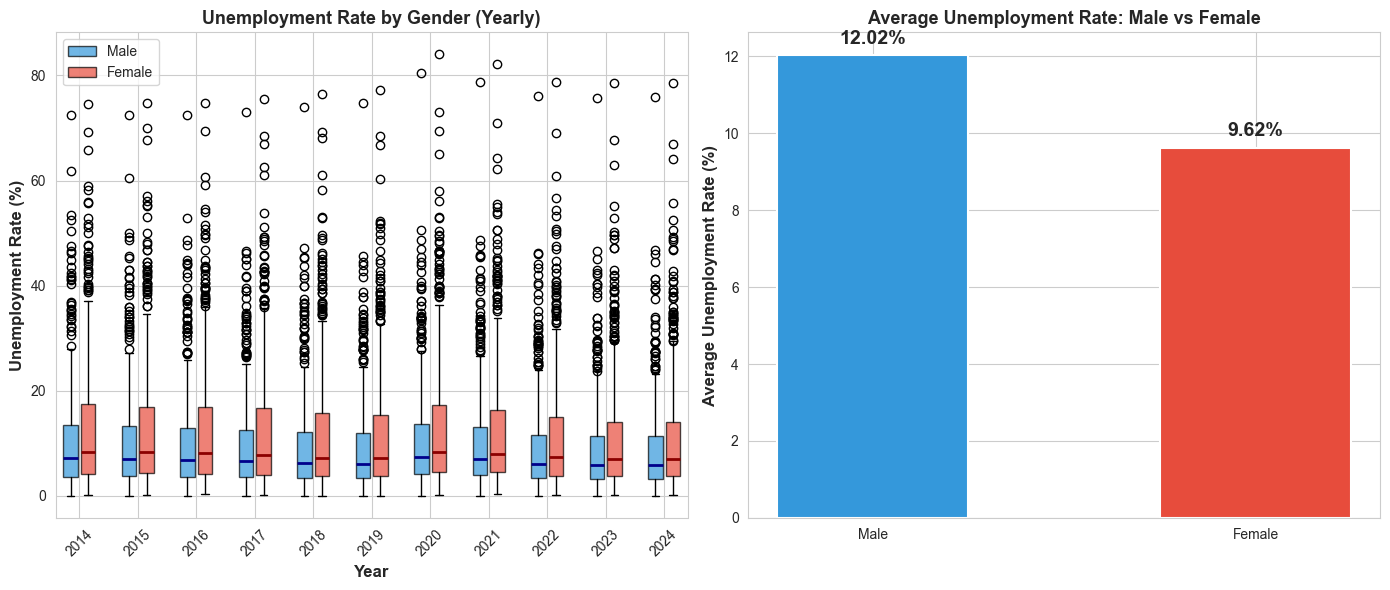

Fig.2: Female unemployment systematically higher than male across all years.


In [68]:
# Fig.2: Gender comparison — boxplot + bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
male_data = [df[df['sex']=='Male'][y].dropna().values for y in year_cols]
female_data = [df[df['sex']=='Female'][y].dropna().values for y in year_cols]
pos_m = np.arange(len(year_cols)) * 2 - 0.3
pos_f = np.arange(len(year_cols)) * 2 + 0.3

bp1 = axes[0].boxplot(male_data, positions=pos_m, widths=0.5,
                       patch_artist=True,
                       boxprops=dict(facecolor='#3498db', alpha=0.7),
                       medianprops=dict(color='darkblue', linewidth=2))
bp2 = axes[0].boxplot(female_data, positions=pos_f, widths=0.5,
                       patch_artist=True,
                       boxprops=dict(facecolor='#e74c3c', alpha=0.7),
                       medianprops=dict(color='darkred', linewidth=2))
axes[0].set_xticks(np.arange(len(year_cols)) * 2)
axes[0].set_xticklabels(year_cols, rotation=45)
axes[0].set_xlabel('Year', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Unemployment Rate by Gender (Yearly)', fontsize=13, fontweight='bold')
axes[0].legend([bp1['boxes'][0], bp2['boxes'][0]], ['Male', 'Female'], fontsize=10)

gender_means = df.groupby('sex')['avg_unemployment'].mean()
bars = axes[1].bar(['Male', 'Female'], gender_means.values,
                    color=['#3498db', '#e74c3c'], edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, gender_means.values):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                f'{val:.2f}%', ha='center', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Average Unemployment Rate: Male vs Female', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig2_gender_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.2: Female unemployment systematically higher than male across all years.')

### 4.4 Age Group Analysis + Fig.3

In [69]:
age_stats = df.groupby('age_categories').agg({
    'avg_unemployment': ['mean', 'std', 'min', 'max'],
    'trend_2014_2024': 'mean', 'covid_impact': 'mean'
}).round(3)
display(age_stats)
age_stats.to_csv(f'{OUTPUT_DIR}/age_stats.csv', encoding='utf-8-sig')
y_mean = df[df.age_categories=='Youth']['avg_unemployment'].mean()
a_mean = df[df.age_categories=='Adults']['avg_unemployment'].mean()
print(f'Youth avg: {y_mean:.2f}% (highest), Adults avg: {a_mean:.2f}% (lowest)')

avg_unemployment                        trend_2014_2024  \
                           mean     std    min     max            mean   
age_categories                                                           
Adults                    6.430   5.355  0.048  28.581          -0.829   
Children                  8.067   6.358  0.065  36.520          -1.215   
Youth                    17.961  13.166  0.221  77.721          -2.299   

               covid_impact  
                       mean  
age_categories               
Adults                0.782  
Children              0.874  
Youth                 2.012

Youth avg: 17.96% (highest), Adults avg: 6.43% (lowest)


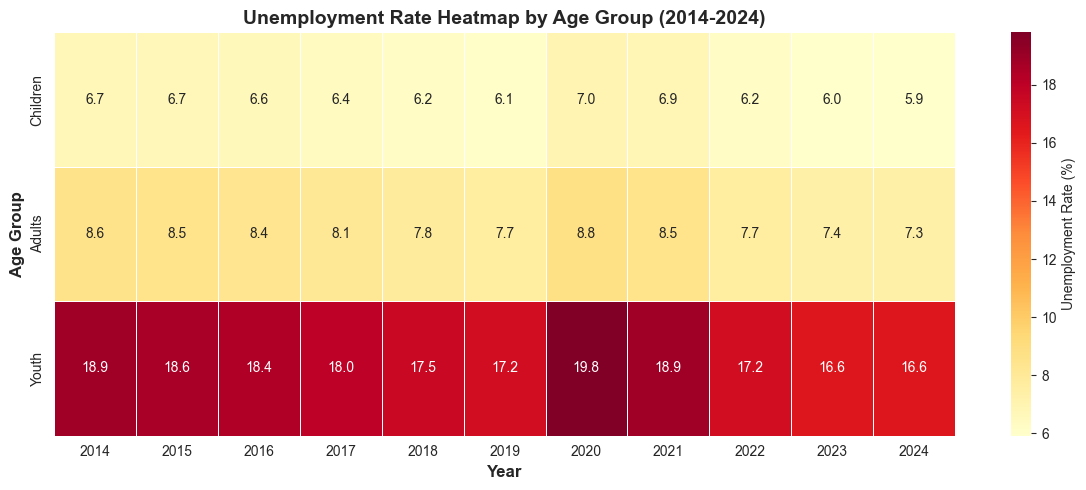

Fig.3: Youth row is darkest (highest unemployment); all groups darkened in 2020 (COVID).


In [70]:
# Fig.3: Age Group Heatmap
fig, ax = plt.subplots(figsize=(12, 5))
age_yearly = df.groupby('age_categories').agg({y: 'mean' for y in year_cols})
age_yearly.index = ['Children', 'Adults', 'Youth']
sns.heatmap(age_yearly, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Unemployment Rate (%)'},
            ax=ax, annot_kws={'fontsize': 10})
ax.set_title('Unemployment Rate Heatmap by Age Group (2014-2024)', fontsize=14, fontweight='bold')
ax.set_xlabel('Year', fontsize=12, fontweight='bold')
ax.set_ylabel('Age Group', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig3_age_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.3: Youth row is darkest (highest unemployment); all groups darkened in 2020 (COVID).')

### 4.5 Fig.4 — Distribution Histogram

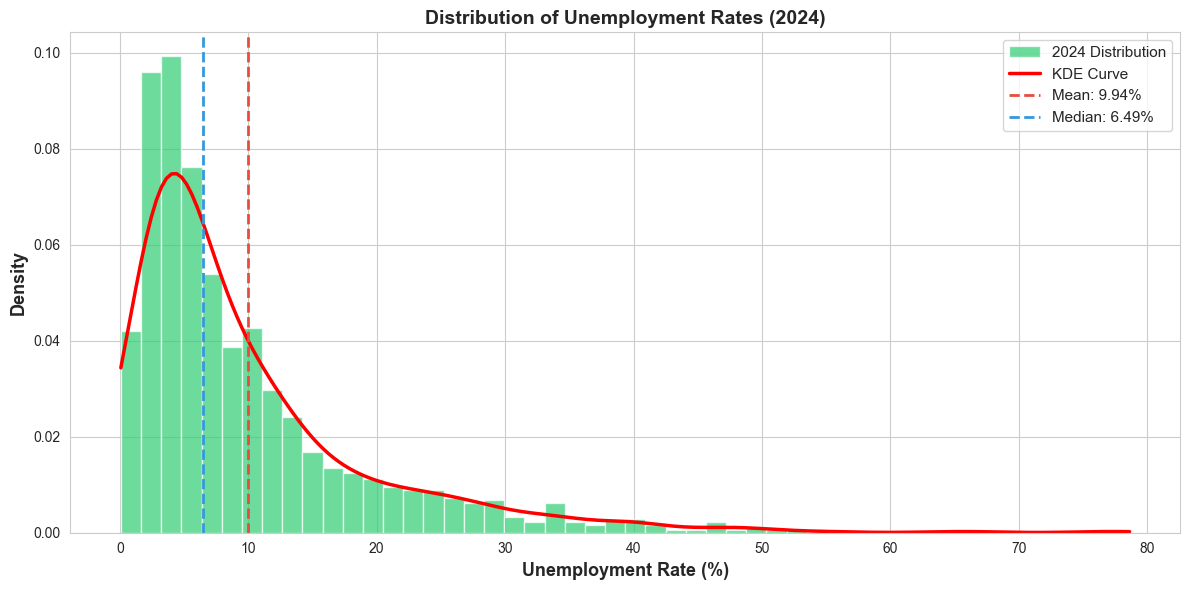

Fig.4: Right-skewed distribution — mean (9.94%) > median (6.49%).


In [71]:
# Fig.4: Distribution of 2024 unemployment rates
fig, ax = plt.subplots(figsize=(12, 6))
data_2024 = df['2024'].dropna()
ax.hist(data_2024, bins=50, color='#2ecc71', edgecolor='white',
        alpha=0.7, density=True, label='2024 Distribution')
kde = gaussian_kde(data_2024)
x_range = np.linspace(data_2024.min(), data_2024.max(), 200)
ax.plot(x_range, kde(x_range), 'r-', linewidth=2.5, label='KDE Curve')
ax.axvline(data_2024.mean(), color='#e74c3c', linestyle='--', linewidth=2,
           label=f'Mean: {data_2024.mean():.2f}%')
ax.axvline(data_2024.median(), color='#3498db', linestyle='--', linewidth=2,
           label=f'Median: {data_2024.median():.2f}%')
ax.set_xlabel('Unemployment Rate (%)', fontsize=13, fontweight='bold')
ax.set_ylabel('Density', fontsize=13, fontweight='bold')
ax.set_title('Distribution of Unemployment Rates (2024)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig4_distribution_histogram.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Fig.4: Right-skewed distribution — mean ({data_2024.mean():.2f}%) > median ({data_2024.median():.2f}%).')

### 4.6 Fig.5 — COVID-19 Impact Scatter

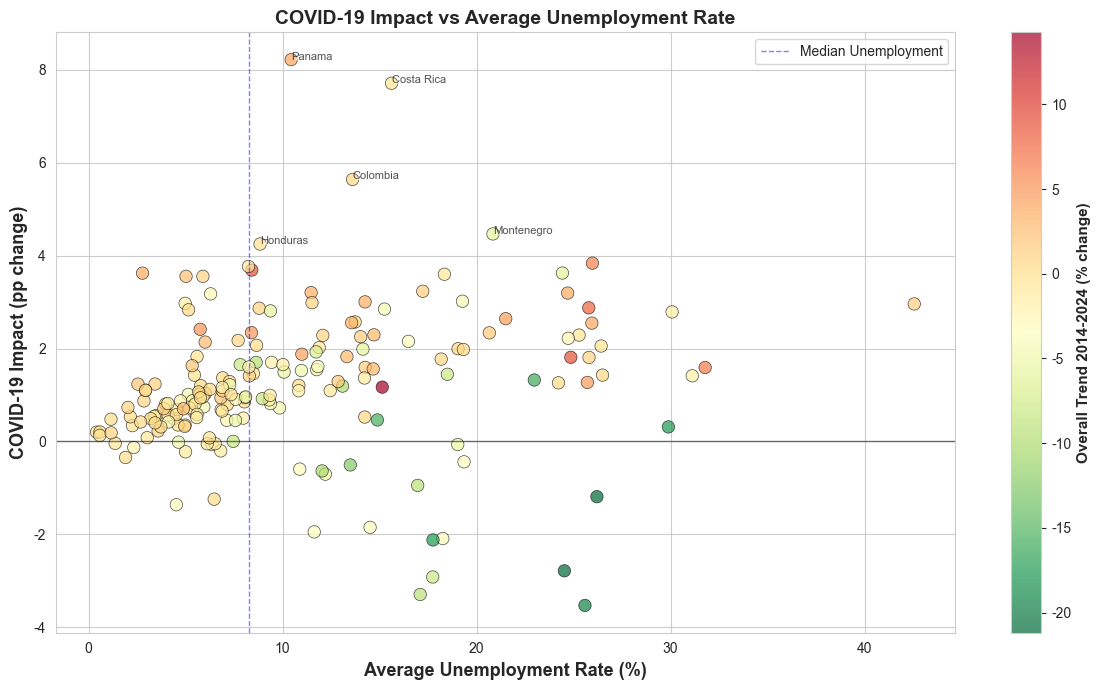

Fig.5: Most countries above y=0 (positive COVID impact); higher-unemployment countries hit harder.


In [72]:
# Fig.5: COVID-19 impact scatter
fig, ax = plt.subplots(figsize=(12, 7))
country_covid = df.groupby('country_name').agg({
    'covid_impact': 'mean', 'avg_unemployment': 'mean', 'trend_2014_2024': 'mean'
}).reset_index()
scatter = ax.scatter(country_covid['avg_unemployment'], country_covid['covid_impact'],
                     c=country_covid['trend_2014_2024'], cmap='RdYlGn_r',
                     s=80, alpha=0.7, edgecolors='black', linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Overall Trend 2014-2024 (% change)', fontsize=11, fontweight='bold')
ax.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
ax.axvline(x=country_covid['avg_unemployment'].median(), color='blue',
           linestyle='--', linewidth=1, alpha=0.5, label='Median Unemployment')
extreme = country_covid.nlargest(5, 'covid_impact')
for _, row in extreme.iterrows():
    ax.annotate(row['country_name'],
                (row['avg_unemployment'], row['covid_impact']),
                fontsize=8, alpha=0.8, arrowprops=dict(arrowstyle='->', alpha=0.5))
ax.set_xlabel('Average Unemployment Rate (%)', fontsize=13, fontweight='bold')
ax.set_ylabel('COVID-19 Impact (pp change)', fontsize=13, fontweight='bold')
ax.set_title('COVID-19 Impact vs Average Unemployment Rate', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig5_covid_impact_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.5: Most countries above y=0 (positive COVID impact); higher-unemployment countries hit harder.')

### 4.7 Global Yearly Summary

In [73]:
yearly_global = pd.DataFrame({
    'Year': [int(y) for y in year_cols],
    'Global_Mean': [df[y].mean() for y in year_cols],
    'Global_Median': [df[y].median() for y in year_cols],
    'Global_Std': [df[y].std() for y in year_cols]
}).set_index('Year')
display(yearly_global.round(3))
yearly_global.to_csv(f'{OUTPUT_DIR}/yearly_global_trend.csv', encoding='utf-8-sig')

,Global_Mean,Global_Median,Global_Std
Year,,,
2014,11.388,7.698,11.119
2015,11.272,7.547,10.916
2016,11.123,7.504,10.743
2017,10.864,7.140,10.641
2018,10.516,6.706,10.528
2019,10.311,6.627,10.298
2020,11.851,8.067,11.232
2021,11.423,7.542,10.873
2022,10.340,6.624,10.238


### 4.8 Fig.6 — Gender x Age Group Cross Analysis

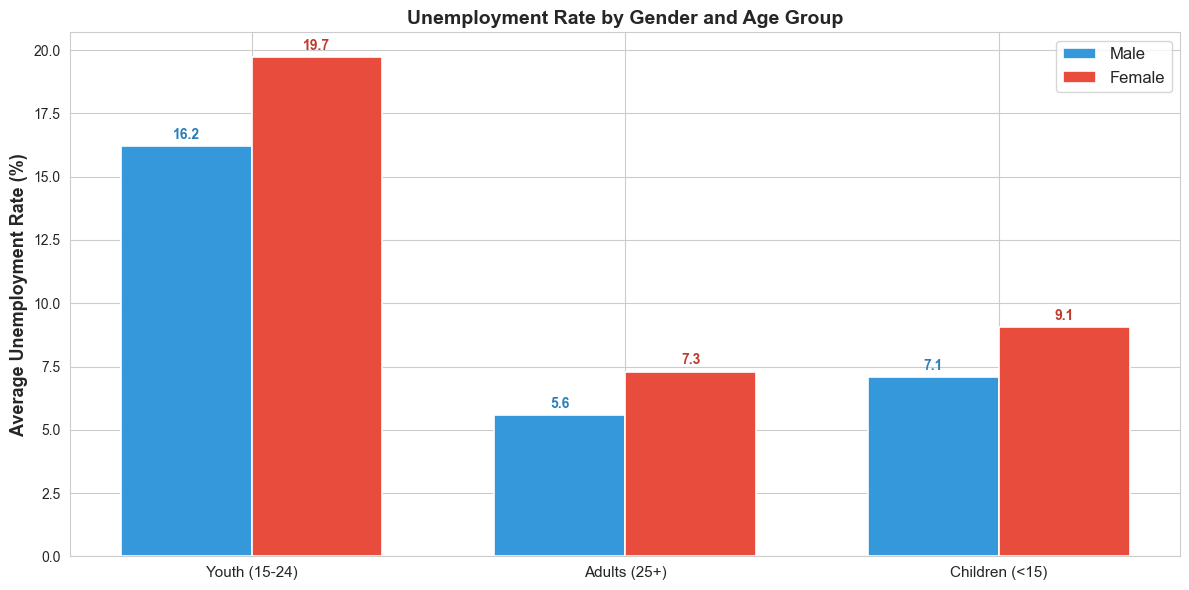

Fig.6: Female youth have the highest unemployment rate across all groups.


In [74]:
# Fig.6: Gender x Age Group bar chart
fig, ax = plt.subplots(figsize=(12, 6))
cross_stats = df.groupby(['sex', 'age_categories'])['avg_unemployment'].mean().unstack()
cross_stats = cross_stats[['Youth', 'Adults', 'Children']]
x = np.arange(len(cross_stats.columns))
width = 0.35
bars1 = ax.bar(x - width/2, cross_stats.loc['Male'], width, label='Male',
               color='#3498db', edgecolor='white', linewidth=1.2)
bars2 = ax.bar(x + width/2, cross_stats.loc['Female'], width, label='Female',
               color='#e74c3c', edgecolor='white', linewidth=1.2)
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', fontsize=10, fontweight='bold', color='#2980b9')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
            f'{bar.get_height():.1f}', ha='center', fontsize=10, fontweight='bold', color='#c0392b')
ax.set_xticks(x)
ax.set_xticklabels(['Youth (15-24)', 'Adults (25+)', 'Children (<15)'], fontsize=11)
ax.set_ylabel('Average Unemployment Rate (%)', fontsize=13, fontweight='bold')
ax.set_title('Unemployment Rate by Gender and Age Group', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig6_gender_age_barchart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.6: Female youth have the highest unemployment rate across all groups.')

### 4.9 Fig.7 — Top 30 Countries + Fig.8 — Age Group Trends

In [75]:
country_summary = df.groupby('country_name')['avg_unemployment'].mean().sort_values(ascending=False)
country_summary.to_csv(f'{OUTPUT_DIR}/country_summary.csv', encoding='utf-8-sig')
covid_country_impact = df.groupby('country_name')['covid_impact'].mean().sort_values(ascending=False)
covid_country_impact.to_csv(f'{OUTPUT_DIR}/covid_impact.csv', encoding='utf-8-sig')
print('Top 5 highest unemployment:')
for c, v in country_summary.head(5).items():
    print(f'  {c}: {v:.2f}%')
print('Top 5 lowest unemployment:')
for c, v in country_summary.tail(5).items():
    print(f'  {c}: {v:.2f}%')

Top 5 highest unemployment:
  Djibouti: 42.56%
  South Africa: 31.78%
  Libya: 31.12%
  Eswatini: 30.08%
  Palestinian Territories: 29.89%
Top 5 lowest unemployment:
  Solomon Islands: 1.16%
  Chad: 1.15%
  Niger: 0.59%
  Qatar: 0.58%
  Cambodia: 0.41%


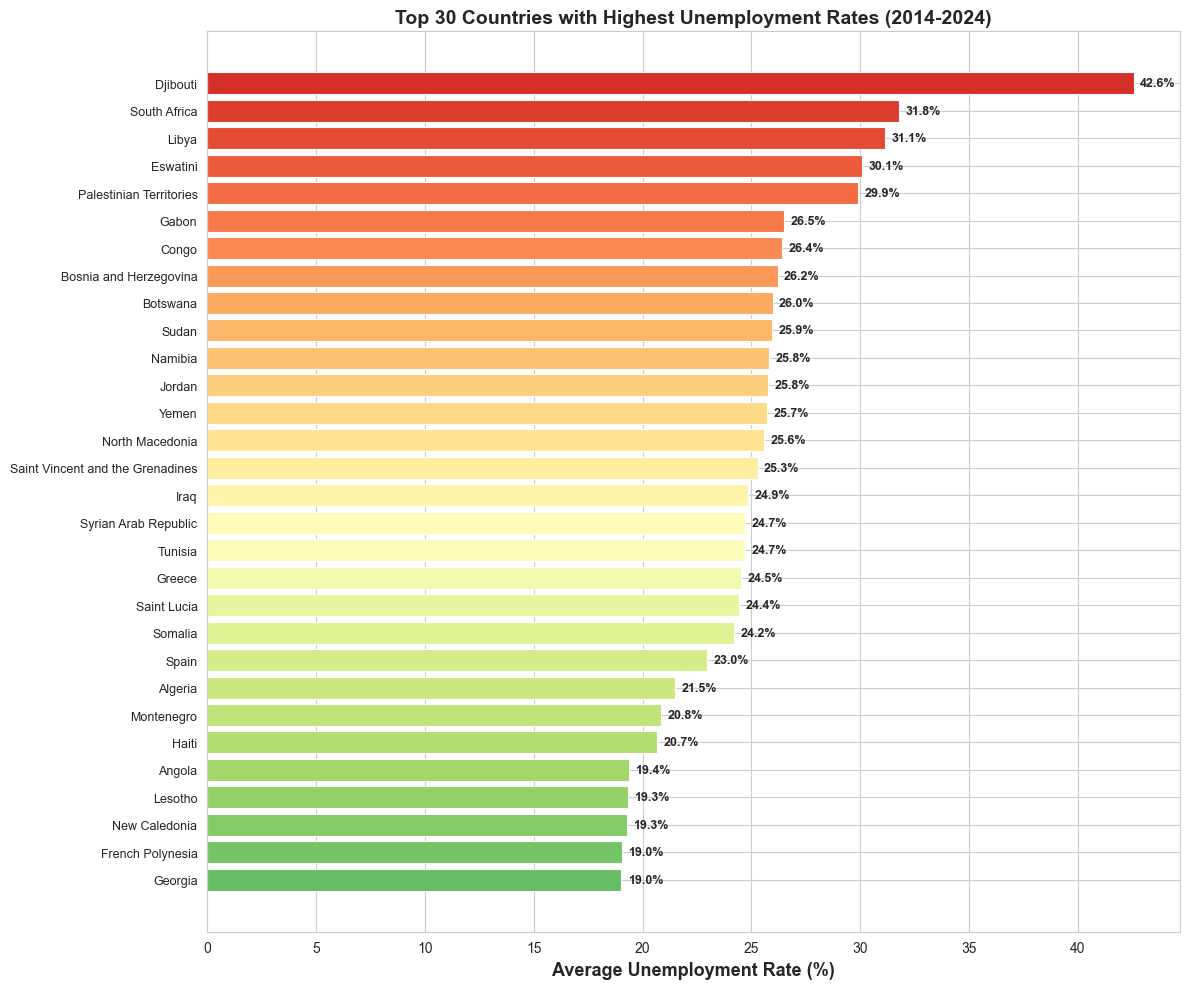

Fig.7: Top-ranked countries are mostly developing economies, rates above 15%.


In [76]:
# Fig.7: Top 30 countries (horizontal bar)
fig, ax = plt.subplots(figsize=(12, 10))
top30 = country_summary.head(30).sort_values(ascending=True)
colors_bar = plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, len(top30)))
bars = ax.barh(top30.index, top30.values, color=colors_bar, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, top30.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
            f'{val:.1f}%', va='center', fontsize=9, fontweight='bold')
ax.set_xlabel('Average Unemployment Rate (%)', fontsize=13, fontweight='bold')
ax.set_title('Top 30 Countries with Highest Unemployment Rates (2014-2024)', fontsize=14, fontweight='bold')
ax.tick_params(axis='y', labelsize=9)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig7_top30_countries.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.7: Top-ranked countries are mostly developing economies, rates above 15%.')

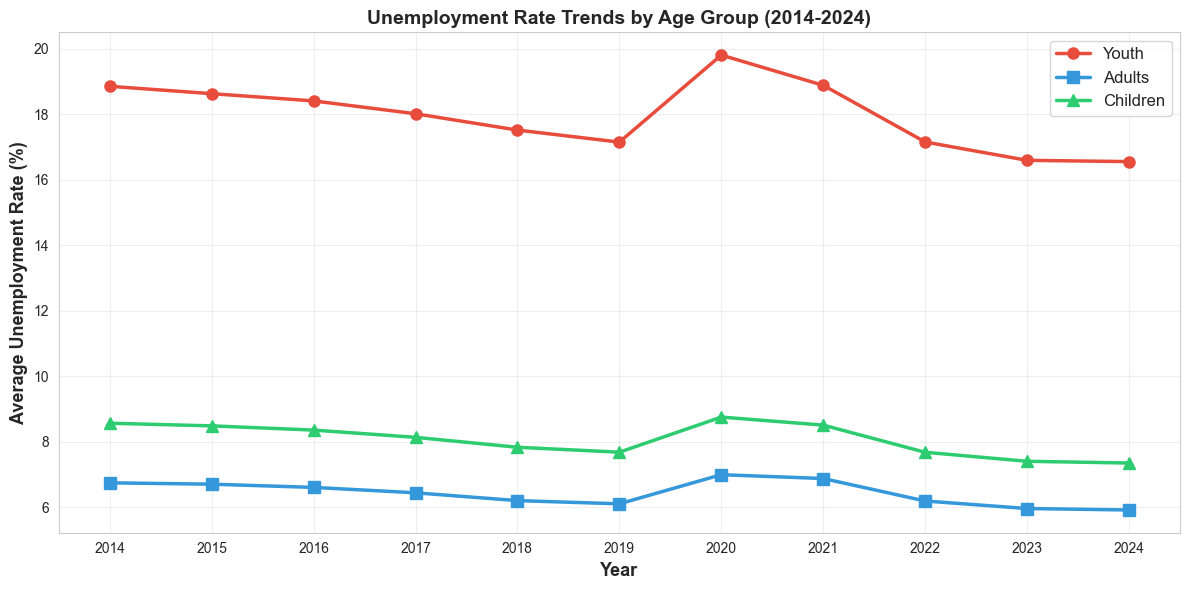

Fig.8: Youth rate is much higher than Adults and Children in every year, with highest volatility.


In [77]:
# Fig.8: Age group trend lines
fig, ax = plt.subplots(figsize=(12, 6))
age_groups = df['age_categories'].unique()
colors_line = ['#e74c3c', '#3498db', '#2ecc71']
markers = ['o', 's', '^']
for age, color, marker in zip(age_groups, colors_line, markers):
    age_data = df[df['age_categories'] == age]
    yearly_mean = [age_data[y].mean() for y in year_cols]
    ax.plot(years_int, yearly_mean, marker=marker, color=color,
            linewidth=2.5, markersize=8, label=age)
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Average Unemployment Rate (%)', fontsize=13, fontweight='bold')
ax.set_title('Unemployment Rate Trends by Age Group (2014-2024)', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
ax.set_xticks(years_int)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig8_age_trends.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.8: Youth rate is much higher than Adults and Children in every year, with highest volatility.')

---
## 5. Statistical Tests

### 5.1 Independent t-test: Male vs Female

In [78]:
male_avg = df[df['sex'] == 'Male']['avg_unemployment']
female_avg = df[df['sex'] == 'Female']['avg_unemployment']
t_stat, p_value = stats.ttest_ind(male_avg, female_avg)
print(f'Male: {male_avg.mean():.3f}% (std={male_avg.std():.3f})')
print(f'Female: {female_avg.mean():.3f}% (std={female_avg.std():.3f})')
print(f't-statistic: {t_stat:.4f}, p-value: {p_value:.6f}')
print(f'Conclusion: {"SIGNIFICANT" if p_value < 0.05 else "NOT significant"} (p<0.05)')

pd.DataFrame({
    'Metric': ['Male Mean', 'Female Mean', 'Male Std', 'Female Std', 't-statistic', 'p-value', 'Significant'],
    'Value': [male_avg.mean(), female_avg.mean(), male_avg.std(), female_avg.std(), t_stat, p_value, 'Yes' if p_value < 0.05 else 'No']
}).to_csv(f'{OUTPUT_DIR}/ttest_result.csv', index=False, encoding='utf-8-sig')

Male: 9.617% (std=8.889)
Female: 12.022% (std=11.470)
t-statistic: -3.9465, p-value: 0.000084
Conclusion: SIGNIFICANT (p<0.05)


### 5.2 One-Way ANOVA: Age Groups

In [79]:
youth = df[df['age_categories'] == 'Youth']['avg_unemployment']
adults = df[df['age_categories'] == 'Adults']['avg_unemployment']
children = df[df['age_categories'] == 'Children']['avg_unemployment']
f_stat, p_value_anova = stats.f_oneway(youth, adults, children)
print(f'Youth: {youth.mean():.3f}%, Adults: {adults.mean():.3f}%, Children: {children.mean():.3f}%')
print(f'F-statistic: {f_stat:.4f}, p-value: {p_value_anova:.6f}')
print(f'Conclusion: {"SIGNIFICANT" if p_value_anova < 0.05 else "NOT significant"} difference among age groups')

pd.DataFrame({
    'Metric': ['Youth Mean','Adults Mean','Children Mean','Youth Std','Adults Std','Children Std','F-statistic','p-value','Significant'],
    'Value': [youth.mean(), adults.mean(), children.mean(), youth.std(), adults.std(), children.std(), f_stat, p_value_anova, 'Yes' if p_value_anova < 0.05 else 'No']
}).to_csv(f'{OUTPUT_DIR}/anova_result.csv', index=False, encoding='utf-8-sig')

Youth: 17.961%, Adults: 6.430%, Children: 8.067%
F-statistic: 182.0480, p-value: 0.000000
Conclusion: SIGNIFICANT difference among age groups


---
## 6. Machine Learning Models & Result Charts (Fig.9-12)
> Charts in this section visualize modeling results — model selection, predictions, feature importance, dimensionality reduction.

### 6.1 K-Means Clustering + Fig.9 (Elbow Method)

In [80]:
# K-Means Clustering
cluster_features = df.groupby('country_name').agg({
    'avg_unemployment': 'mean', 'volatility': 'mean',
    'trend_2014_2024': 'mean', 'covid_impact': 'mean'
})
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_features)

inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_features['Cluster'] = kmeans.fit_predict(X_scaled)
cluster_features.to_csv(f'{OUTPUT_DIR}/kmeans_clusters.csv', encoding='utf-8-sig')

print('Clustering results (K=4):')
for i in range(4):
    c_data = cluster_features[cluster_features['Cluster'] == i]
    print(f'  Cluster {i}: {len(c_data)} countries, avg rate={c_data["avg_unemployment"].mean():.2f}%')

Clustering results (K=4):
  Cluster 0: 95 countries, avg rate=5.65%
  Cluster 1: 31 countries, avg rate=11.12%
  Cluster 2: 53 countries, avg rate=17.99%
  Cluster 3: 10 countries, avg rate=21.01%


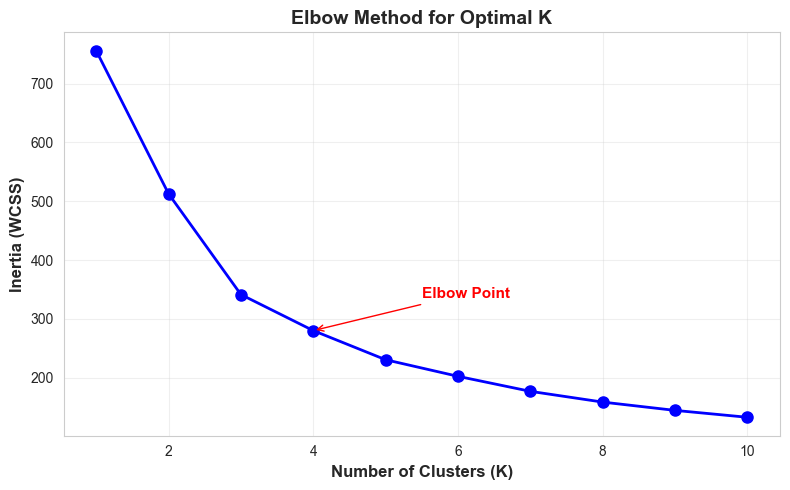

Fig.9: Clear elbow at K=4, so 4 clusters is optimal.


In [81]:
# Fig.9 (Model Chart): Elbow Method
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(K_range, inertias, 'bo-', markersize=8, linewidth=2)
ax.set_xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
ax.set_ylabel('Inertia (WCSS)', fontsize=12, fontweight='bold')
ax.set_title('Elbow Method for Optimal K', fontsize=14, fontweight='bold')
ax.annotate('Elbow Point', xy=(4, inertias[3]), xytext=(5.5, inertias[3]*1.2),
            arrowprops=dict(arrowstyle='->', color='red'), fontsize=11, fontweight='bold', color='red')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig9_elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.9: Clear elbow at K=4, so 4 clusters is optimal.')

### 6.2 Linear Regression + Fig.10 (Forecast)

In [82]:
# Linear Regression
years_arr = np.array(years_int).reshape(-1, 1)
global_means_arr = np.array([df[y].mean() for y in year_cols])
lr_model = LinearRegression()
lr_model.fit(years_arr, global_means_arr)
y_pred_lr = lr_model.predict(years_arr)
future_years = np.array(range(2025, 2031)).reshape(-1, 1)
future_pred = lr_model.predict(future_years)
r2_lr = r2_score(global_means_arr, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(global_means_arr, y_pred_lr))
mae_lr = mean_absolute_error(global_means_arr, y_pred_lr)
print(f'R2={r2_lr:.4f}, RMSE={rmse_lr:.4f}, MAE={mae_lr:.4f}')
print(f'Slope: {lr_model.coef_[0]:.4f}%/year')
for yr, pred in zip(range(2025, 2031), future_pred):
    print(f'  {yr}: {pred:.2f}%')

pd.DataFrame({
    'Year': list(range(2014, 2031)),
    'Type': ['Actual']*11 + ['Predicted']*6,
    'Unemployment_Rate': list(global_means_arr) + list(future_pred)
}).to_csv(f'{OUTPUT_DIR}/linear_regression_results.csv', index=False, encoding='utf-8-sig')

R2=0.3345, RMSE=0.4980, MAE=0.3611
Slope: -0.1117%/year
  2025: 10.15%
  2026: 10.04%
  2027: 9.93%
  2028: 9.81%
  2029: 9.70%
  2030: 9.59%


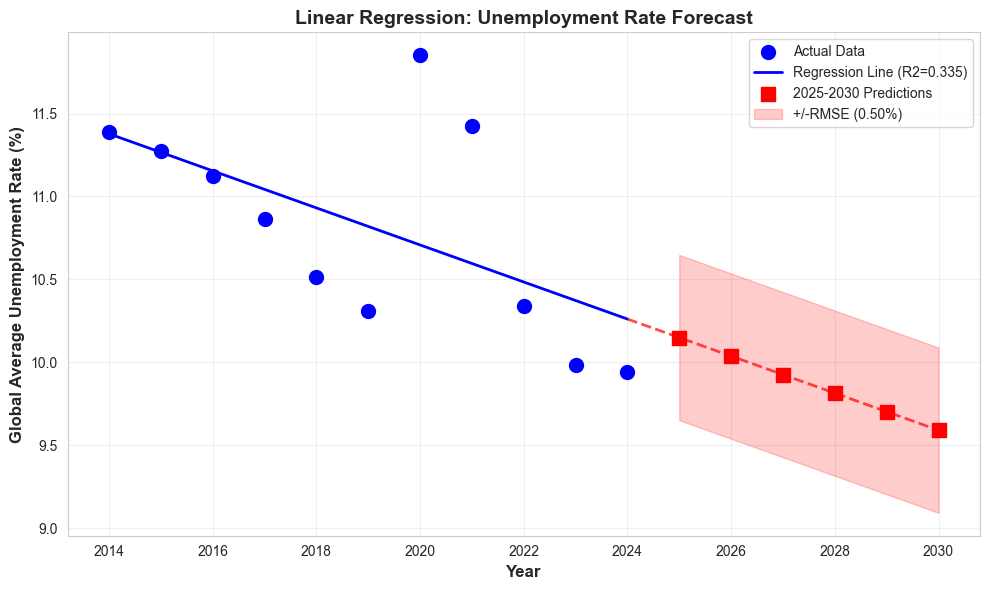

Fig.10: Linear regression shows slight downward trend in global unemployment.


In [83]:
# Fig.10 (Model Chart): Linear Regression Forecast
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(years_arr, global_means_arr, color='blue', s=100, zorder=5, label='Actual Data')
ax.plot(years_arr, y_pred_lr, 'b-', linewidth=2, label=f'Regression Line (R2={r2_lr:.3f})')
ax.scatter(future_years, future_pred, color='red', s=100, zorder=5, marker='s', label='2025-2030 Predictions')
ax.plot(np.vstack([years_arr[-1:], future_years]),
        np.hstack([y_pred_lr[-1:], future_pred]), 'r--', linewidth=2, alpha=0.7)
ax.fill_between(future_years.ravel(),
                future_pred.ravel() - rmse_lr,
                future_pred.ravel() + rmse_lr,
                alpha=0.2, color='red', label=f'+/-RMSE ({rmse_lr:.2f}%)')
ax.set_xlabel('Year', fontsize=12, fontweight='bold')
ax.set_ylabel('Global Average Unemployment Rate (%)', fontsize=12, fontweight='bold')
ax.set_title('Linear Regression: Unemployment Rate Forecast', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig10_linear_regression.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.10: Linear regression shows slight downward trend in global unemployment.')

### 6.3 Random Forest Regression + Fig.11 (Feature Importance & Prediction)

In [84]:
# Random Forest
df_encoded = df.copy()
le_sex = LabelEncoder()
le_age = LabelEncoder()
le_country = LabelEncoder()
df_encoded['sex_encoded'] = le_sex.fit_transform(df_encoded['sex'])
df_encoded['age_encoded'] = le_age.fit_transform(df_encoded['age_group'])
df_encoded['country_encoded'] = le_country.fit_transform(df_encoded['country_name'])

feature_cols = ['sex_encoded', 'age_encoded', 'country_encoded',
                '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
X = df_encoded[feature_cols]
y = df_encoded['2024']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, max_depth=10)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)
print(f'RF R2={rf_r2:.4f}, RMSE={rf_rmse:.4f}, MAE={rf_mae:.4f}')

feature_importance = pd.DataFrame({
    'Feature': feature_cols, 'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)
display(feature_importance)
feature_importance.to_csv(f'{OUTPUT_DIR}/rf_feature_importance.csv', index=False, encoding='utf-8-sig')

RF R2=0.9965, RMSE=0.4610, MAE=0.2752


,Feature,Importance
12,2023,0.969482
11,2022,0.009677
10,2021,0.007747
8,2019,0.003170
7,2018,0.002179
9,2020,0.002004
5,2016,0.001594
6,2017,0.001453
3,2014,0.001259
4,2015,0.000907


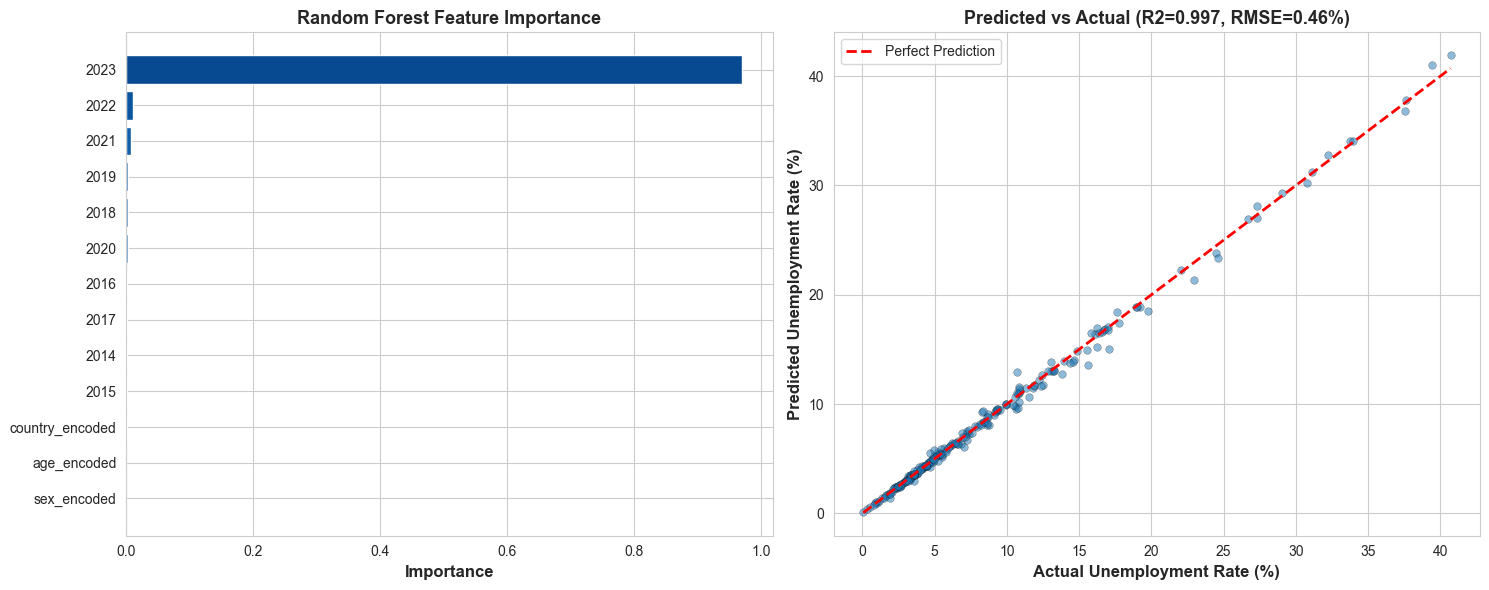

Fig.11: RF achieves high R2; recent year data and country are the most important features.


In [85]:
# Fig.11 (Model Chart): RF Feature Importance + Predicted vs Actual
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(feature_importance['Feature'][::-1], feature_importance['Importance'][::-1],
             color=plt.cm.Blues(np.linspace(0.4, 0.9, len(feature_importance))))
axes[0].set_xlabel('Importance', fontsize=12, fontweight='bold')
axes[0].set_title('Random Forest Feature Importance', fontsize=13, fontweight='bold')

axes[1].scatter(y_test, y_pred_rf, alpha=0.5, s=30, edgecolors='black', linewidth=0.3)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', linewidth=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Predicted Unemployment Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_title(f'Predicted vs Actual (R2={rf_r2:.3f}, RMSE={rf_rmse:.2f}%)', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig11_random_forest.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.11: RF achieves high R2; recent year data and country are the most important features.')

### 6.4 PCA Dimensionality Reduction + Fig.12 (Explained Variance & PC Space)

In [86]:
# PCA
pca_data = df.groupby('country_name')[year_cols].mean()
scaler_pca = StandardScaler()
pca_scaled = scaler_pca.fit_transform(pca_data)
pca = PCA()
pca_result = pca.fit_transform(pca_scaled)
explained_var = pca.explained_variance_ratio_
cumsum_var = np.cumsum(explained_var)
print('Explained variance ratio:')
for i in range(5):
    print(f'  PC{i+1}: {explained_var[i]*100:.2f}% (cumulative: {cumsum_var[i]*100:.2f}%)')
print(f'First 2 PCs explain {cumsum_var[1]*100:.1f}% of total variance.')

pd.DataFrame({
    'Country': pca_data.index,
    'PC1': pca_result[:, 0], 'PC2': pca_result[:, 1], 'PC3': pca_result[:, 2]
}).to_csv(f'{OUTPUT_DIR}/pca_results.csv', index=False, encoding='utf-8-sig')

Explained variance ratio:
  PC1: 94.00% (cumulative: 94.00%)
  PC2: 4.06% (cumulative: 98.06%)
  PC3: 1.19% (cumulative: 99.25%)
  PC4: 0.32% (cumulative: 99.57%)
  PC5: 0.18% (cumulative: 99.75%)
First 2 PCs explain 98.1% of total variance.


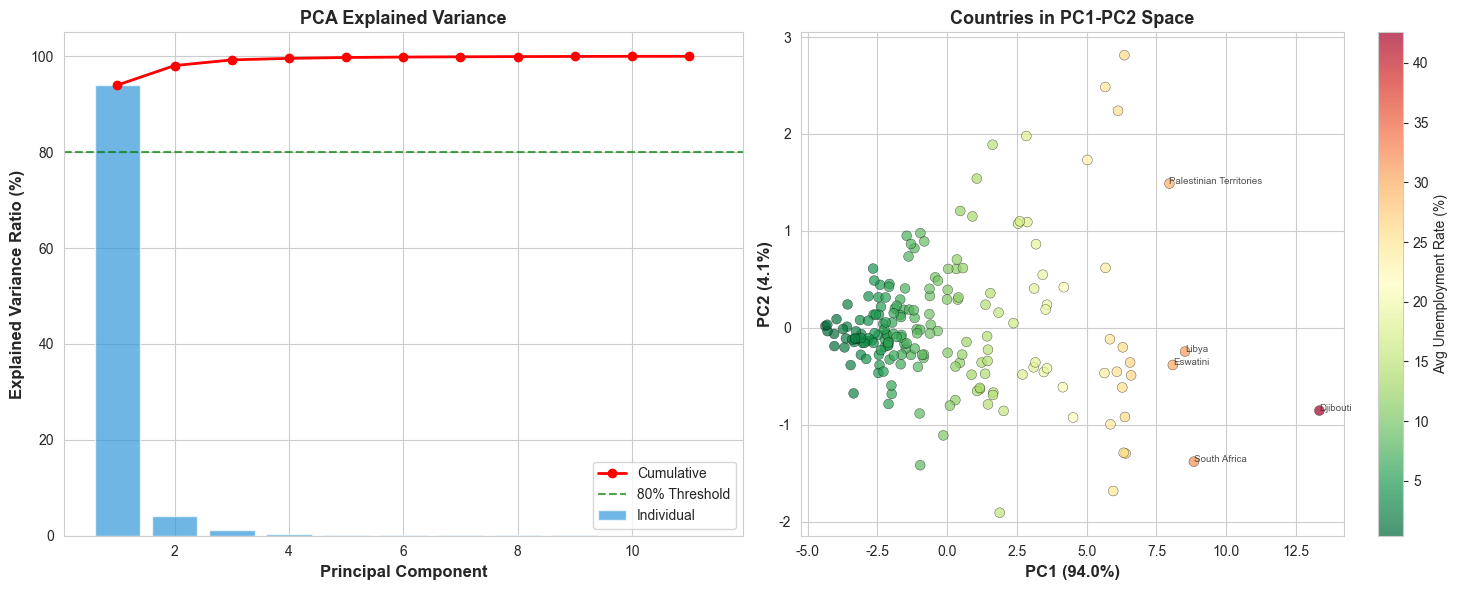

Fig.12: PC1 alone explains >90% variance; countries spread along PC1 by unemployment level.


In [87]:
# Fig.12 (Model Chart): PCA Explained Variance + PC1-PC2 Space
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].bar(range(1, len(explained_var)+1), explained_var*100, alpha=0.7, color='#3498db', label='Individual')
axes[0].plot(range(1, len(explained_var)+1), cumsum_var*100, 'ro-', linewidth=2, markersize=6, label='Cumulative')
axes[0].axhline(y=80, color='green', linestyle='--', alpha=0.7, label='80% Threshold')
axes[0].set_xlabel('Principal Component', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Explained Variance Ratio (%)', fontsize=12, fontweight='bold')
axes[0].set_title('PCA Explained Variance', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)

scatter2 = axes[1].scatter(pca_result[:, 0], pca_result[:, 1],
                          c=pca_data.mean(axis=1), cmap='RdYlGn_r',
                          s=50, alpha=0.7, edgecolors='black', linewidth=0.3)
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Avg Unemployment Rate (%)', fontsize=10)
axes[1].set_xlabel(f'PC1 ({explained_var[0]*100:.1f}%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel(f'PC2 ({explained_var[1]*100:.1f}%)', fontsize=12, fontweight='bold')
axes[1].set_title('Countries in PC1-PC2 Space', fontsize=13, fontweight='bold')
extreme_idx = np.argsort(np.abs(pca_result[:, 0]))[-5:]
for idx in extreme_idx:
    axes[1].annotate(pca_data.index[idx], (pca_result[idx, 0], pca_result[idx, 1]),
                    fontsize=7, alpha=0.8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig12_pca_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig.12: PC1 alone explains >90% variance; countries spread along PC1 by unemployment level.')

---
## 7. Project Summary

In [88]:
summary = f"""
============================================================
  Global Unemployment Data Analysis — Project Summary
============================================================

[1] Data Overview
  - Source: International Labour Organization (ILO)
  - Records: {df.shape[0]}, Countries: {df['country_name'].nunique()}
  - Time: 2014-2024 | Dimensions: Sex + Age Group

[2] Key Findings (Data Exploration Charts Fig.1-8)
  - Global unemployment shows slight downward trend, COVID spike in 2020
  - Female unemployment systematically higher than male
  - Youth (15-24) unemployment much higher than other age groups
  - Distribution is right-skewed — few high-unemployment countries pull up mean

[3] Statistical Tests
  - t-test: Gender difference is SIGNIFICANT (p={p_value:.6f})
  - ANOVA: Age group differences are SIGNIFICANT (p={p_value_anova:.6f})

[4] ML Models (Result Charts Fig.9-12)
  - K-Means: 4 country clusters by unemployment patterns
  - Linear Regression: R2={r2_lr:.4f}, RMSE={rmse_lr:.4f}%
  - Random Forest: R2={rf_r2:.4f}, RMSE={rf_rmse:.4f}%
  - PCA: First 2 PCs explain {cumsum_var[1]*100:.1f}% variance

[5] Output Files in output/ folder:
  - Data Exploration Charts: fig1~fig8 (8 charts)
  - Model Result Charts: fig9~fig12 (4 charts)
  - CSV statistics files + analysis summary
============================================================
"""
print(summary)
with open(f'{OUTPUT_DIR}/analysis_summary.txt', 'w', encoding='utf-8') as f:
    f.write(summary)


  Global Unemployment Data Analysis — Project Summary

[1] Data Overview
  - Source: International Labour Organization (ILO)
  - Records: 1134, Countries: 189
  - Time: 2014-2024 | Dimensions: Sex + Age Group

[2] Key Findings (Data Exploration Charts Fig.1-8)
  - Global unemployment shows slight downward trend, COVID spike in 2020
  - Female unemployment systematically higher than male
  - Youth (15-24) unemployment much higher than other age groups
  - Distribution is right-skewed — few high-unemployment countries pull up mean

[3] Statistical Tests
  - t-test: Gender difference is SIGNIFICANT (p=0.000084)
  - ANOVA: Age group differences are SIGNIFICANT (p=0.000000)

[4] ML Models (Result Charts Fig.9-12)
  - K-Means: 4 country clusters by unemployment patterns
  - Linear Regression: R2=0.3345, RMSE=0.4980%
  - Random Forest: R2=0.9965, RMSE=0.4610%
  - PCA: First 2 PCs explain 98.1% variance

[5] Output Files in output/ folder:
  - Data Exploration Charts: fig1~fig8 (8 charts)
  -

In [89]:
print('='*60)
print('Output files:')
print('='*60)
for file in sorted(os.listdir(OUTPUT_DIR)):
    size_kb = os.path.getsize(os.path.join(OUTPUT_DIR, file)) / 1024
    tag = '[Data Chart]' if file.startswith('fig') and int(file[3]) <= 8 else (
          '[Model Chart]' if file.startswith('fig') else '[Stats]')
    print(f'  {file} ({size_kb:.1f} KB) {tag}')
print(f'\nTotal: {len(os.listdir(OUTPUT_DIR))} files')
print('Run: streamlit run streamlit_app.py')

Output files:
  age_stats.csv (0.3 KB) [Stats]
  analysis_summary.txt (1.3 KB) [Stats]
  anova_result.csv (0.3 KB) [Stats]
  country_summary.csv (5.6 KB) [Stats]
  covid_impact.csv (5.5 KB) [Stats]
  descriptive_stats.csv (0.7 KB) [Stats]
  fig10_linear_regression.png (80.9 KB) [Data Chart]
  fig11_random_forest.png (117.7 KB) [Data Chart]
  fig12_pca_analysis.png (154.7 KB) [Data Chart]
  fig1_global_trend.png (88.9 KB) [Data Chart]
  fig2_gender_comparison.png (141.2 KB) [Data Chart]
  fig3_age_heatmap.png (64.0 KB) [Data Chart]
  fig4_distribution_histogram.png (74.0 KB) [Data Chart]
  fig5_covid_impact_scatter.png (174.3 KB) [Data Chart]
  fig6_gender_age_barchart.png (53.6 KB) [Data Chart]
  fig7_top30_countries.png (131.1 KB) [Data Chart]
  fig8_age_trends.png (84.0 KB) [Data Chart]
  fig9_elbow_method.png (48.2 KB) [Model Chart]
  gender_stats.csv (0.3 KB) [Stats]
  kmeans_clusters.csv (16.1 KB) [Stats]
  linear_regression_results.csv (0.6 KB) [Stats]
  pca_results.csv (13.2 KB)